In [2]:
import os

from keras.src.ops import shape

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

I0000 00:00:1792829362.705416   18513 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.22.0-rc0


<h2>1. Différence entre TensorFlow et Keras ? </h2> 
<h4>-TensorFlow est le moteur de calcul. Il gère les tenseurs, les calculs sur CPU/GPU et le calcul automatique des gradients.  
-Keras est une API de haut niveau placée au-dessus de TensorFlow (tf.keras). Elle permet de construire un réseau en quelques lignes.


<h2>2. À quoi sert Flatten ?</h2> 
<h4>Elle transforme une image 2D de 28×28 en un vecteur 1D de 784 valeurs (28 × 28 = 784).


<h2>3. Quelle version de TensorFlow est installée ?</h2>
 <h4>TensorFlow version: 2.22.0-rc0

<h2>4. À quoi servent Sequential et Dense ?</h2>
<h4>Sequential est un conteneur qui empile les couches les unes après les autres, en ligne droite : la sortie d’une couche est l’entrée de la suivante.
<h4>Dense est une couche entièrement connectée : chaque neurone est relié à tous les neurones de la couche précédente. Elle calcule sortie = activation(W*x + b).

In [3]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape :", x_test.shape)
print("y_test shape :", y_test.shape)
print("dtype        :", x_train.dtype)
print("pixel min/max:", x_train.min(), x_train.max())
print("Un exemple de label:", y_train[0])


x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape : (10000, 28, 28)
y_test shape : (10000,)
dtype        : uint8
pixel min/max: 0 255
Un exemple de label: 5


In [4]:
# normalisation
x_train=x_train/255.0
x_test = x_test / 255.0
print("pixel min/max apres:", x_train.min(), x_train.max())

pixel min/max apres: 0.0 1.0


<h2>1. Pourquoi normalise-t-on les pixels ?
<h4>Pour ramener les valeurs de [0, 255] à [0, 1].

<h2>2. Taille d’une image et type de données ?
<h4> Taille : 28 × 28 pixels, en niveaux de gris, donc 1 seul canal.
<h4>Type : uint8 (entiers de 0 à 255) avant normalisation, puis float64 après la division par 255.0.

<h2>3. Combien d’exemples dans le jeu d’entraînement ?
<h4>60 000.

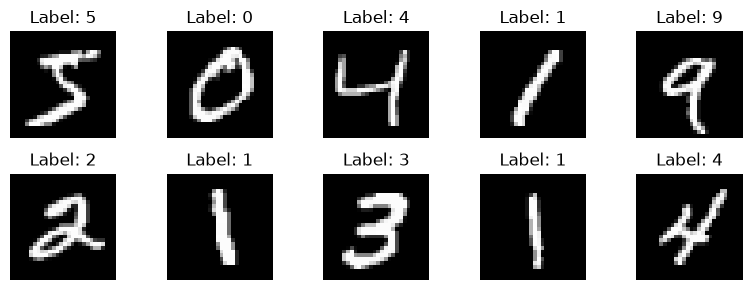

In [6]:

plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()  
plt.show()

<h2>1. Quelle commande modifie le nombre d’images affichées ?
<h4>Il faut changer range(10) et adapter la grille plt.subplot(lignes, colonnes, i+1)
<h2>2. Que représente cmap='gray' ?
<h4>C’est la palette de couleurs (colormap) utilisée pour afficher l’image. Avec 'gray', 0 s’affiche en noir et 1 (ou 255) en blanc.
<h2>3. Quelle utilité a cette étape dans un projet d’IA ?
<h4>Elle permet de vérifier la qualité des données avant l’entraînement

In [5]:
import tensorflow as tf

model = Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

<h2> 1. Combien de paramètres le modèle contient-il ?
<h4>Formule d’une couche Dense : (entrées × neurones) + neurones  
Flatten : 0 paramètre  

Dense(128) : 784 × 128 + 128 = 100 352 + 128 = 100 480  

Dense(10) : 128 × 10 + 10 = 1 280 + 10 = 1 290  

Total : 101 770 paramètres  
<h2>2. Quelle activation dans la couche de sortie ? Pourquoi ?
<h4>Softmax. Elle transforme les 10 sorties en probabilités positives dont la somme vaut 1.




In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

<h2>1. Qu’est-ce qu’un optimiseur ?
<h4>C’est l’algorithme qui met à jour les poids pour réduire la perte, à partir des gradients calculés par la rétropropagation. Exemples : SGD, RMSprop, Adam.


<h2>2. Pourquoi utilise-t-on une fonction de perte ?
<h4>Elle mesure l’erreur entre la prédiction et la vraie valeur, sous forme d’un seul nombre.


<h2>3. Que se passe-t-il si on change la fonction de perte ?
<h4>Le modèle optimise un autre objectif. Une perte inadaptée donne de mauvais résultats, ou une erreur.


<h2>4. Conséquence d’un mauvais choix d’optimiseur ?

<h4>Convergence très lente
Perte qui oscille ou diverge (pas trop grand)
Blocage dans un mauvais minimum local ou sur un plateau

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5


W0000 00:00:1792854935.103711   18513 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


1863/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9255 - loss: 0.2609

W0000 00:00:1792854954.025118   18513 cpu_allocator_impl.cc:174] Allocation of 31360000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9257 - loss: 0.2601 - val_accuracy: 0.9587 - val_loss: 0.1371
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9661 - loss: 0.1129 - val_accuracy: 0.9691 - val_loss: 0.0989
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9778 - loss: 0.0768 - val_accuracy: 0.9728 - val_loss: 0.0883
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9835 - loss: 0.0565 - val_accuracy: 0.9740 - val_loss: 0.0843
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9879 - loss: 0.0425 - val_accuracy: 0.9755 - val_loss: 0.0814


<h1>1. Que représente une époque ?
<h4>Un passage complet sur les 60 000 images d’entraînement.
<h1>2. Pourquoi un jeu de validation ?
<h4>Pour mesurer la généralisation pendant l’entraînement, sur des images que le modèle n’utilise pas pour apprendre.
<h1>3. Que se passerait-il avec 50 époques ?
<h4>
L’accuracy d’entraînement approcherait 100 %.  

La validation plafonnerait vers 97,5 à 98 %, puis pourrait baisser légèrement.  

Le modèle commencerait à mémoriser les données d’entraînement : c’est le surapprentissage (overfitting).  

Le temps de calcul serait 10 fois plus long, pour un gain faible.



In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

 22/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9759 - loss: 0.0716

W0000 00:00:1792855620.812627   18513 cpu_allocator_impl.cc:174] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9755 - loss: 0.0814
Test accuracy: 0.9755
Test loss: 0.0814


<h2>1. Quelle est la précision finale de votre modèle ?
<h4>Environ 97,5 à 98 %, c’est-à-dire que le modèle se trompe sur environ 200 images parmi les 10 000 du test. Recopie la valeur affichée sur ta machine.
<h2>2. Pourquoi la précision du test est souvent inférieure à celle d’entraînement ?
<h4>Parce que le modèle a optimisé ses poids sur les images d’entraînement, qu’il a donc vues et en partie « mémorisées ». Les images de test sont nouvelles pour lui.
<h1>3. Que faire si le modèle surapprend ?
<h4>
Dropout : désactiver aléatoirement des neurones pendant l’entraînement  

EarlyStopping : arrêter quand la validation ne progresse plus  

Régularisation L1/L2 : pénaliser les poids trop grands  

Plus de données ou Data Augmentation  

Modèle plus simple : moins de couches ou de neurones  


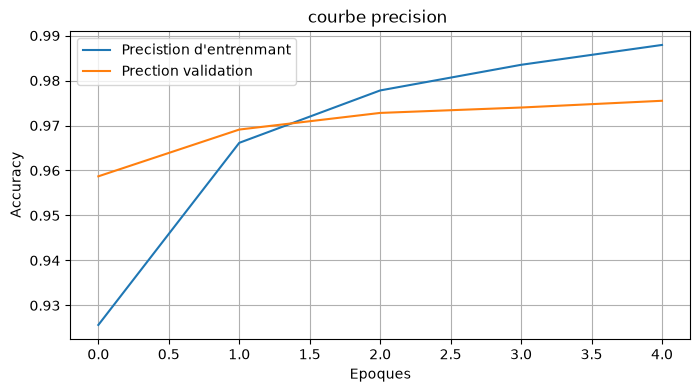

In [10]:
plt.figure(figsize=(8,4))

plt.plot(history.history['accuracy'],label="Precistion d'entrenmant")
plt.plot(history.history['val_accuracy'],label="Prection validation")
plt.title("courbe precision ")
plt.xlabel("Epoques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

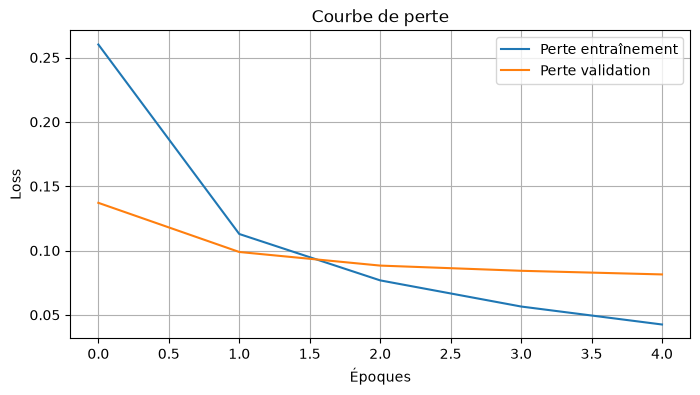

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

<h1>1. Que remarquez-vous sur les deux courbes ?
<h4>
La courbe d’entraînement monte régulièrement (de 0,92 vers 0,98).
La courbe de validation monte aussi, mais plus vite au début, puis se stabilise vers 0,975 à 0,98.
Les deux restent proches : le modèle apprend bien, avec un léger début de décrochage possible à la fin.
<h1>
2. Comment détecter visuellement un surapprentissage ?
<h4>Quand la courbe d’entraînement continue de monter alors que celle de validation stagne ou redescend. Côté perte, c’est l’inverse : la loss d’entraînement baisse mais la loss de validation remonte. L’écart entre les deux courbes s’agrandit.
<h1>
3. Quelle stratégie pour y remédier ?
<h4>
Dropout, EarlyStopping, régularisation, plus de données

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


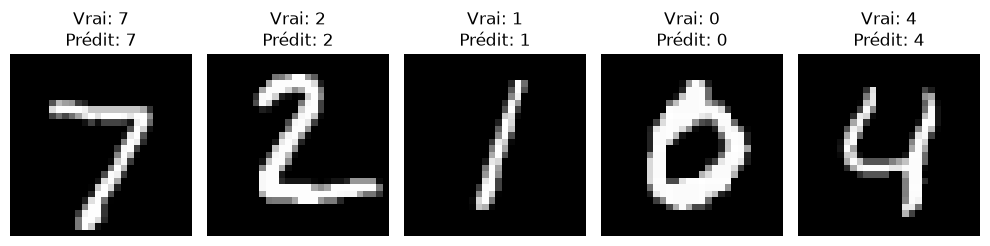

In [22]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

<h1>1. Le modèle fait-il des erreurs ? Sur quelles images ?
<h4>Oui, environ 2 % d’erreurs (≈ 200 images sur 10 000). Elles portent surtout sur des chiffres mal écrits ou ambigus et sur des paires de chiffres qui se ressemblent : 4 / 9, 3 / 5, 7 / 1, 2 / 7.
<h1>
2. Comment expliquer une prédiction erronée ?
<h4>
Le chiffre est ambigu, même pour un humain.
Le réseau Dense ne voit pas la structure spatiale : il traite l’image comme 784 nombres indépendants, donc un chiffre légèrement décalé ou incliné le perturbe.
Le modèle est simple (une seule couche cachée) et entraîné peu longtemps.

<h1>3. Quelle technique améliorerait la précision ?
<h4>Un CNN indépendamment de leur position. Il atteint environ 99 % sur MNIST .